# C08d — WaveDetect: competitors, RAFT and NS11
Run top to bottom in a fresh kernel inside reproduction. Reads all ten saved 54-case arms. Loads the completed C07 WaveDetect checkpoint; no base detector retraining and no rewrite generation.

Frozen evaluation uses the original Qwen/Morlet/ResNet implementation, BF16 autocast and fixed 1024-token padding. New runtime-aware per-document caches keep previous C07 outputs untouched. All arms appear together.

**New C08d adaptation protocol:** select every non-OG arm with full54 AUROC <0.8. Use the saved C08b 20/34 source split. Initialize each continuation from the frozen C07 checkpoint, train all parameters for three epochs at 1e-5 with linear decay, logical batch8/microbatch1 and the original loss. Select by original RAID validation loss. Train a separate RAID-only continuation control. This is not asserted to reproduce the earlier C07 adaptation cell, which was unavailable in the source notebook.

Training checkpoints every ten optimizer updates and at epoch boundaries; completed scores save individually. Restart and rerun to resume. Neural adaptation can take substantial time; only one model is on GPU. Full model and optimizer checkpoints need several GB per arm. No test scores select checkpoints. Full54 adaptation selection is exploratory, since it includes the eventual34. Human domain weighting matches the evaluated cohort. Bootstrap intervals condition on fitted models, split and human references. RAFT/NS11 retain their quality/fidelity caveats.


In [1]:
from pathlib import Path
import os, json, hashlib, tempfile, io, math, random, gc, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.checkpoint import checkpoint
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, ResNetConfig, ResNetModel
from huggingface_hub import snapshot_download
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
           if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()), None)
assert ROOT is not None, 'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
C07=ROOT/'results/causal/C07_WaveDetect_RAID_OG_NS10_v1'
FROZEN=C07/'wavedetect_raid_best.pt'
assert FROZEN.exists(),'Missing completed C07 checkpoint.'
OUT=ROOT/'results/causal/C08d_WaveDetect_competitors_RAFT_NS11_v1'
OUT.mkdir(parents=True,exist_ok=True)
for name in ['tokens','scores']: (OUT/name).mkdir(exist_ok=True)
SEED=20260922
BASE_LM='Qwen/Qwen2.5-0.5B'
MAX_LENGTH=1024
MICROBATCH=1
BATCH=8
EPOCHS=(3,3)
LRS=(1e-3,1e-5)
SAVE_EVERY=10
assert torch.cuda.is_available(), 'CUDA GPU required for this training configuration.'
assert torch.cuda.is_bf16_supported(), 'This configuration requires BF16 support.'
DEVICE=torch.device('cuda')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True

def digest(b): return hashlib.sha256(b).hexdigest()
def text_sha(t): return digest(str(t).encode())
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
def atomic(path,writer):
    path=Path(path); fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'wb') as f: writer(f); f.flush(); os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp): os.unlink(tmp)
def save_json(x,p): atomic(p,lambda f:f.write(json.dumps(x,sort_keys=True,indent=2,allow_nan=False).encode()))
def save_csv(df,p): atomic(p,lambda f:f.write(df.to_csv(index=False).encode()))
def save_torch(x,p): atomic(p,lambda f:torch.save(x,f))
def freeze(x,p):
    if p.exists(): assert json.loads(p.read_text())==x, f'Contract changed: use a new OUT directory ({p}).'
    else: save_json(x,p)
print('Output:',OUT)
print('GPU:',torch.cuda.get_device_name(), '| free GB:',round(torch.cuda.mem_get_info()[0]/1e9,2))

import fcntl
from contextlib import contextmanager
@contextmanager
def run_lock():
 with (OUT/"run.lock").open("a") as f:
  fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
  try:yield
  finally:fcntl.flock(f,fcntl.LOCK_UN)
ADAPT=OUT
ADAPT_SEED=20260923


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/C08d_WaveDetect_competitors_RAFT_NS11_v1
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU | free GB: 6.7


In [2]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)

raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all(), 'Source-group split leakage'
raid['text_sha']=raid.text.map(text_sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all(), 'Identical text spans multiple splits'
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
assert tr.label.nunique()==va.label.nunique()==2
save_csv(raid.drop(columns='text'),OUT/'RAID_manifest.csv')
save_csv(ns[['case_id','source_id','domain','text_sha']],OUT/'NS10_manifest.csv')
display(raid.groupby(['split','label']).size().rename('n').to_frame())


C08=ROOT/'results/causal/C08_Ghostbuster_only_RAID54_v1'
RELEASED=C08/'released_checkpoints_v1'
FILES={
 'HIP_RAID_0.6B':C08/'HIP_RAID_0.6B_texts.csv',
 'MASH_RAID_GB':C08/'MASH_RAID_GB_texts.csv',
 'UTS_SYNTH_RECON':C08/'UTS_SYNTH_RECON_texts.csv',
 'UTS_STREAM_RECON':C08/'UTS_STREAM_RECON_texts.csv',
 'HIP_RELEASED_4B':RELEASED/'HIP_RELEASED_4B_texts.csv',
 'StealthRL_RELEASED_4B':RELEASED/'StealthRL_RELEASED_4B_texts.csv',
}
ARMS=list(FILES)
LABELS=dict(zip(ARMS,['HIP limited','MASH limited','UTS SYNTH limited','UTS STREAM limited','HIP released 4B','StealthRL released 4B']))

FILES.update({'OG_RAFT':ROOT/'results/causal/R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv',
 'NS11':ROOT/'results/causal/R11_NS10_RAFT_v1/NS11_texts.csv'})
ARMS=list(FILES);LABELS.update({'OG_RAFT':'OG → RAFT','NS11':'NS11'})
frames={'OG':og.copy(),'NS10':ns[['case_id','source_id','domain','text']].copy()}
for arm,path in FILES.items():
 f=pd.read_csv(path,keep_default_na=False)
 assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(ns.case_id)
 f=f.set_index('case_id').loc[ns.case_id].reset_index()
 assert f.source_id.astype(str).tolist()==ns.source_id.astype(str).tolist()
 assert f.domain.tolist()==ns.domain.tolist() and f.text.str.strip().ne('').all()
 if 'text_sha' in f:assert f.text_sha.eq(f.text.map(text_sha)).all()
 frames[arm]=f[['case_id','source_id','domain','text']].copy()
case_ids=sorted(ns.case_id.tolist())
split=json.loads((ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/split.json').read_text())
chosen=split['adaptation_cases'];held=split['test_cases']
assert len(chosen)==20 and len(held)==34 and not set(chosen)&set(held)
assert set(chosen)|set(held)==set(case_ids)
freeze(split,OUT/'split.json')
manifest=[dict(arm=k,case_id=r.case_id,source_id=r.source_id,text_sha=text_sha(r.text)) for k,f in frames.items() for r in f.itertuples()]
freeze(manifest,OUT/'rewrite_inputs.json')
for k,f in frames.items():
 fit=pd.concat([tr,f.loc[f.case_id.isin(chosen)]])
 test=pd.concat([va,raid.loc[raid.split.eq('test')&raid.label.eq(0)],f.loc[f.case_id.isin(held)]])
 assert not set(fit.text.map(text_sha))&set(test.text.map(text_sha)),f'Text overlap: {k}'


n
split      label     
test       0      138
           1      138
train      0      636
           1      636
validation 0      135
           1      135

In [3]:
# Resolve and persist one immutable base-LM snapshot revision before loading weights.
base_revision=json.loads((C07/'base_revision.json').read_text())['revision']
snapshot=Path(snapshot_download(BASE_LM,revision=base_revision))
tokenizer=AutoTokenizer.from_pretrained(snapshot)
if tokenizer.pad_token_id is None: tokenizer.pad_token=tokenizer.eos_token
tokenizer.padding_side='right'
old_contract=json.loads((C07/'contract.json').read_text())
OLD_SHA=text_sha(json.dumps(old_contract,sort_keys=True))
FROZEN_SHA=file_sha(FROZEN)
contract=dict(version='C08d_v1',frozen_sha=FROZEN_SHA,original_contract=old_contract,
 torch=str(torch.__version__),transformers=transformers.__version__,max_length=MAX_LENGTH,
 adaptation_epochs=3,adaptation_lr=1e-5,logical_batch=BATCH,microbatch=MICROBATCH,seed=SEED,
 selection='minimum original RAID validation loss',split=split,
 raid_texts=text_sha(json.dumps(raid[['source_id','split','label','text_sha']].to_dict('records'),sort_keys=True)))
freeze(contract,OUT/'contract.json')
CONTRACT_SHA=text_sha(json.dumps(contract,sort_keys=True))

def encode(text):
    key=text_sha(text); path=OUT/'tokens'/(key+'.pt')
    if path.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True)
        assert obj['contract']==CONTRACT_SHA
        return obj
    full=tokenizer(str(text),add_special_tokens=True)['input_ids']
    assert len(full)>=2, 'Document has fewer than two tokens'
    ids=full[:MAX_LENGTH]; n=len(ids)
    obj=dict(contract=CONTRACT_SHA,input_ids=torch.tensor(ids+[tokenizer.pad_token_id]*(MAX_LENGTH-n)),
             attention_mask=torch.tensor([1]*n+[0]*(MAX_LENGTH-n)),tokens_total=len(full),tokens_used=n,
             truncated=len(full)>MAX_LENGTH)
    save_torch(obj,path); return obj
all_texts=pd.concat([raid[['text']],*[f[['text']] for f in frames.values()]]).drop_duplicates('text')
for t in tqdm(all_texts.text,desc='Tokenize/cache'): encode(t)
print('Base LM revision:',base_revision)


Tokenize/cache: 100%|████████████████████████████████████████████████████████████████████████████████| 2304/2304 [00:00<00:00, 2893.39it/s]

Base LM revision: 060db6499f32faf8b98477b0a26969ef7d8b9987


In [4]:
class WaveletTransform(nn.Module):
    """
    Differentiable continuous wavelet transform (Morlet basis) with padding,
    cropping, and reconstruction.
    Inputs:
        token_probs (B, T)
        attention_mask (B, T) — optional but recommended
    Output:
        wavelet_spectrum (B, 1, num_scales, T)
    """
    def __init__(self, wavelet="morl", num_scales=32, kernel_size=128):
        super().__init__()
        assert wavelet == "morl", "Only Morlet wavelet is supported at this time"
        self.num_scales = num_scales
        self.kernel_size = kernel_size

        # Time axis in [-2, 2]
        self.register_buffer("time", torch.linspace(-2, 2, steps=kernel_size))
        self.sigma = 1.0
        self.freq0 = 5.0
        self.register_buffer("scales", torch.linspace(1.0, num_scales, num_scales))

    def morlet_wavelet(self, scale):
        t = self.time / scale
        wave = torch.exp(-0.5 * (t / self.sigma) ** 2) * torch.cos(2 * math.pi * self.freq0 * t)
        wave = wave / (wave.abs().sum() + 1e-6)
        return wave.view(1, 1, -1)

    def forward(self, token_probs: torch.FloatTensor, attention_mask: torch.FloatTensor = None):
        """
        token_probs: (B, T)
        attention_mask: (B, T)
        return: wavelet_spectrum (B, 1, num_scales, T)
        """
        B, T = token_probs.shape
        device = token_probs.device

        if attention_mask is not None:
            # Compute the valid sequence length for each sample
            valid_lengths = attention_mask.sum(dim=1).long()
        else:
            valid_lengths = torch.full((B,), T, dtype=torch.long, device=device)

        # ========== Wavelet transform ==========
        responses = []
        for i in range(B):
            valid_len = valid_lengths[i].item()
            x_valid = token_probs[i, :valid_len].unsqueeze(0).unsqueeze(0)  # (1, 1, valid_len)
            res_list = []
            for s in self.scales:
                kernel = self.morlet_wavelet(s.to(device)).to(x_valid.dtype)
                pad = self.kernel_size // 2
                conv_real = torch.nn.functional.conv1d(x_valid, kernel, padding=pad)
                res_list.append(conv_real)
            # Stack responses into shape (1, 1, num_scales, valid_len)
            res = torch.stack(res_list, dim=2)
            
            # Restore the original length T by padding zeros on the right
            if valid_len < T:
                pad_size = T - valid_len
                res = torch.nn.functional.pad(res, (0, pad_size))
            responses.append(res)

        responses = torch.cat(responses, dim=0)  # (B, 1, num_scales, T)
        energy = responses.abs()

        return energy



class RaidWaveDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.qwen_model=AutoModelForCausalLM.from_pretrained(snapshot,torch_dtype=torch.bfloat16,
                                                          attn_implementation='sdpa')
        self.qwen_model.config.use_cache=False
        self.qwen_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
        self.wavelet=WaveletTransform(num_scales=16,kernel_size=128)
        cfg=ResNetConfig(num_channels=3,embedding_size=64,hidden_sizes=[64,128,256,512],
                         depths=[2,2,2,2],layer_type='basic',hidden_act='relu',downsample_in_first_stage=False)
        self.cnn=ResNetModel(cfg)
        self.classifier=nn.Linear(512,2)
        self.stage=1
    def set_stage(self,stage):
        self.stage=stage
        self.qwen_model.requires_grad_(stage==2)
    def train(self,mode=True):
        super().train(mode)
        if self.stage==1: self.qwen_model.eval()
        return self
    def projected_probs(self,h,y):
        logits=self.qwen_model.lm_head(h).float()
        return logits.log_softmax(-1).gather(-1,y.unsqueeze(-1)).squeeze(-1).exp()
    def forward(self,input_ids,attention_mask):
        with torch.set_grad_enabled(self.training and self.stage==2):
            h=self.qwen_model.model(input_ids=input_ids,attention_mask=attention_mask,
                                    use_cache=False,return_dict=True).last_hidden_state[:,:-1]
            target=input_ids[:,1:]
            chunks=[]
            for start in range(0,h.shape[1],64):
                args=(h[:,start:start+64],target[:,start:start+64])
                if self.training and self.stage==2:
                    prob=checkpoint(self.projected_probs,*args,use_reentrant=False)
                else: prob=self.projected_probs(*args)
                chunks.append(prob)
            mask=attention_mask[:,:-1]
            probs=torch.cat(chunks,dim=1)*mask
        spectrum=self.wavelet(probs,mask).repeat(1,3,1,1)
        out=self.cnn(spectrum,return_dict=True).last_hidden_state.mean(dim=(2,3))
        return self.classifier(out)

model=RaidWaveDetect().to(DEVICE)
def load_frozen():
 obj=torch.load(FROZEN,map_location='cpu',weights_only=False)
 assert obj['contract']==OLD_SHA
 model.load_state_dict(obj['model']);model.set_stage(2);model.eval()
 del obj;gc.collect();torch.cuda.empty_cache()
load_frozen()

def batch_inputs(frame):
    records=[encode(t) for t in frame.text]
    return {k:torch.stack([r[k] for r in records]).to(DEVICE) for k in ['input_ids','attention_mask']}

def loss_coeff(labels):
    # Exact authors' loss: sum_c [N/(2*n_c)] * mean(losses in class c).
    # This is not the usual sample-weighted CE. Compute once per logical batch.
    n=len(labels);counts=np.bincount(np.asarray(labels,int),minlength=2)
    return np.array([n/(2*counts[int(y)]**2) for y in labels],dtype=np.float32)

@torch.no_grad()
def validation_loss():
    model.eval(); values=[]
    for start in range(0,len(va),BATCH):
        group=va.iloc[start:start+BATCH]; coeff=loss_coeff(group.label.to_numpy()); total=0.
        for j in range(0,len(group),MICROBATCH):
            part=group.iloc[j:j+MICROBATCH]
            with torch.autocast('cuda',dtype=torch.bfloat16): logits=model(**batch_inputs(part))
            ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction='none')
            total+=float((ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum())
        values.append(total)
    return float(np.mean(values))


In [5]:
@torch.no_grad()
def score_frame(frame,name,folder,model_key):
 folder.mkdir(parents=True,exist_ok=True);cache=OUT/'scores'
 model.eval();rows=[]
 for r in tqdm(frame.to_dict('records'),desc=name):
  text=r.pop('text');sha=text_sha(text);key=text_sha(CONTRACT_SHA+model_key+sha)
  p=cache/(key+'.json')
  if p.exists():
   z=json.loads(p.read_text());assert z['text_sha']==sha and z['model_key']==model_key
  else:
   rec=encode(text)
   with torch.autocast('cuda',dtype=torch.bfloat16):
    logits=model(**{k:rec[k].unsqueeze(0).to(DEVICE) for k in ['input_ids','attention_mask']})
   value=float(logits.float().softmax(-1)[0,1]);assert np.isfinite(value)
   z=dict(text_sha=sha,model_key=model_key,AI_score=value,tokens_total=rec['tokens_total'],
          tokens_used=rec['tokens_used'],truncated=rec['truncated'])
   save_json(z,p)
  rows.append({**r,**z})
 out=pd.DataFrame(rows);save_csv(out,folder/(name+'_scores.csv'));return out
with run_lock():
 load_frozen()
 R=score_frame(raid.loc[raid.split.isin(['validation','test'])].copy(),'RAID_eval',OUT,FROZEN_SHA)
 frozen_scores={k:score_frame(f,k,OUT,FROZEN_SHA) for k,f in frames.items()}
display(pd.DataFrame([dict(split=k,AUROC=roc_auc_score(f.label,f.AI_score)) for k,f in R.groupby('split')]))
display(pd.DataFrame([dict(arm=k,cases=len(f),truncated=int(f.truncated.sum())) for k,f in frozen_scores.items()]))


NS11: 100%|██████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 5205.29it/s]


,split,AUROC
0,test,0.789435
1,validation,0.812977


,arm,cases,truncated
0,OG,54,0
1,NS10,54,0
2,HIP_RAID_0.6B,54,0
3,MASH_RAID_GB,54,0
4,UTS_SYNTH_RECON,54,0
5,UTS_STREAM_RECON,54,0
6,HIP_RELEASED_4B,54,0
7,StealthRL_RELEASED_4B,54,0
8,OG_RAFT,54,1
9,NS11,54,0


,arm,detector,cases,AUROC,mean_AI_score
0,OG,Frozen,54,0.797419,0.706225
1,NS10,Frozen,54,0.548795,0.487428
2,HIP_RAID_0.6B,Frozen,54,0.699302,0.615815
3,MASH_RAID_GB,Frozen,54,0.738141,0.598664
4,UTS_SYNTH_RECON,Frozen,54,0.681789,0.584760
5,UTS_STREAM_RECON,Frozen,54,0.741925,0.652639
6,HIP_RELEASED_4B,Frozen,54,0.671270,0.565847
7,StealthRL_RELEASED_4B,Frozen,54,0.775439,0.587493
8,OG_RAFT,Frozen,54,0.586806,0.475397
9,NS11,Frozen,54,0.253375,0.237107


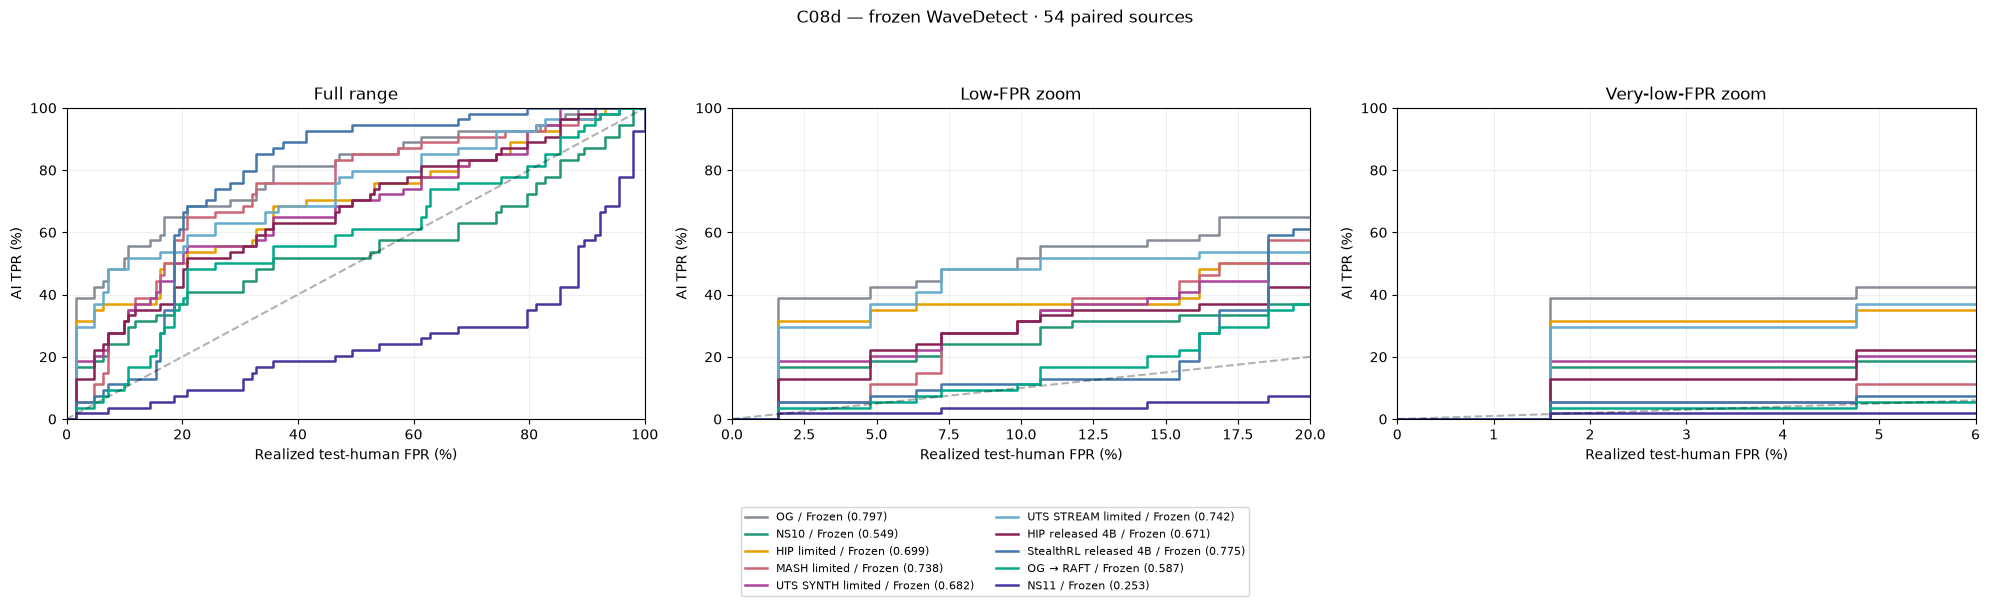

,arm,reference,delta_AUROC,ci_low,ci_high
0,OG,NS10,0.248624,0.142394,0.355446
1,OG,StealthRL_RELEASED_4B,0.021980,-0.062133,0.106219
2,NS10,OG,-0.248624,-0.355446,-0.142394
3,NS10,StealthRL_RELEASED_4B,-0.226644,-0.326409,-0.125467
4,HIP_RAID_0.6B,OG,-0.098117,-0.183932,-0.013612
5,HIP_RAID_0.6B,NS10,0.150507,0.038223,0.260500
6,HIP_RAID_0.6B,StealthRL_RELEASED_4B,-0.076137,-0.168453,0.011271
7,MASH_RAID_GB,OG,-0.059278,-0.162567,0.046566
8,MASH_RAID_GB,NS10,0.189346,0.060093,0.322196
9,MASH_RAID_GB,StealthRL_RELEASED_4B,-0.037298,-0.118678,0.045955


Selected: ['NS10', 'HIP_RAID_0.6B', 'MASH_RAID_GB', 'UTS_SYNTH_RECON', 'UTS_STREAM_RECON', 'HIP_RELEASED_4B', 'StealthRL_RELEASED_4B', 'OG_RAFT', 'NS11']


In [6]:
H=R.loc[R.label.eq(0)].copy()
def references(e):
    mix=e.domain.value_counts(normalize=True)
    def get(split):
        f=H.loc[H.split.eq(split)&H.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts()
        assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain]
        assert np.isclose(f.weight.sum(),1)
        return f
    return get('validation'),get('test')

def measure(e,v,h,ai,vs,hs,arm,detector):
    w=h.weight.to_numpy();cw=v.weight.to_numpy()
    contribution=((ai[:,None]>hs)+.5*(ai[:,None]==hs))@w
    cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
    st=pd.DataFrame(dict(arm=arm,detector=detector,threshold=cuts,
        calibration_FPR=[cw[vs>c].sum() for c in cuts],
        test_FPR=[w[hs>c].sum() for c in cuts],TPR=[(ai>c).mean() for c in cuts]))
    row=dict(arm=arm,detector=detector,cases=len(e),AUROC=float(contribution.mean()),
        mean_AI_score=float(ai.mean()))
    return row,st,contribution

def plot_curves(curves,title,stem,colors):
    fig,axes=plt.subplots(1,3,figsize=(20,6))
    for ax,(xl,yl,name) in zip(axes,[((0,100),(0,100),'Full range'),
        ((0,20),(0,100),'Low-FPR zoom'),((0,6),(0,100),'Very-low-FPR zoom')]):
        for arm,detector,st,value in curves:
            style={'Frozen':'-','RAID-only continuation':':','Own-arm adapted':'--'}[detector]
            ax.step(st.test_FPR*100,st.TPR*100,where='post',lw=1.8,color=colors[arm],
                linestyle=style,label=f'{LABELS.get(arm,arm)} / {detector} ({value:.3f})')
        ax.plot([0,xl[1]],[0,xl[1]],'k--',alpha=.3)
        ax.set(xlim=xl,ylim=yl,title=name,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)')
        ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=2,fontsize=8)
    fig.suptitle(title)
    fig.tight_layout(rect=[0,.20,1,.93])
    for folder in [ADAPT,ROOT/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)


COLORS=dict(zip(frames,['#858C96','#209675','#E69F00','#CC6677','#AA4499','#66AACC','#882255','#4477AA','#00AA88','#4935A0']))
rows=[];curves=[];stairs=[];contrib={}
for arm,e in frozen_scores.items():
 e=e.sort_values('case_id');assert e.case_id.tolist()==case_ids
 v,h=references(e)
 row,st,z=measure(e,v,h,e.AI_score.to_numpy(),v.AI_score.to_numpy(),h.AI_score.to_numpy(),arm,'Frozen')
 rows.append(row);stairs.append(st);contrib[arm]=z;curves.append((arm,'Frozen',st,row['AUROC']))
summary=pd.DataFrame(rows);display(summary.round(6));save_csv(summary,OUT/'frozen54_summary.csv')
save_csv(pd.concat(stairs),OUT/'frozen54_staircases.csv')
plot_curves(curves,'C08d — frozen WaveDetect · 54 paired sources','C08d_WaveDetect_frozen54',COLORS)
ix=np.random.default_rng(ADAPT_SEED).integers(0,54,(5000,54));changes=[]
for arm in frames:
 for ref in ['OG','NS10','StealthRL_RELEASED_4B']:
  if arm==ref:continue
  d=contrib[arm]-contrib[ref];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
  changes.append(dict(arm=arm,reference=ref,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
save_csv(pd.DataFrame(changes),OUT/'frozen54_paired_changes.csv');display(pd.DataFrame(changes))
selected=summary.loc[summary.arm.ne('OG')&summary.AUROC.lt(.8),'arm'].tolist()
freeze(dict(rule='non-OG full54 AUROC < .8',selected=selected),OUT/'selected_arms.json')
print('Selected:',selected)


In [7]:
def continue_model(frame,folder):
 global tr
 tr=frame.sort_values('source_id',kind='stable').reset_index(drop=True)
 folder.mkdir(parents=True,exist_ok=True)
 run=dict(contract=CONTRACT_SHA,training=[dict(source_id=r.source_id,label=int(r.label),text_sha=text_sha(r.text)) for r in tr.itertuples()])
 freeze(run,folder/'training_contract.json')
 RUN_SHA=text_sha(json.dumps(run,sort_keys=True))
 LATEST=folder/'latest.pt';FINAL=folder/'best.pt'
 load_frozen()
 random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
 def cpu_state(m): return {k:v.detach().cpu().clone() for k,v in m.state_dict().items()}
 def rng_state():
     return dict(python=random.getstate(),numpy=np.random.get_state(),cpu=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all())
 def restore_rng(r):
     random.setstate(r['python']);np.random.set_state(r['numpy']);torch.set_rng_state(r['cpu']);torch.cuda.set_rng_state_all(r['cuda'])

 if FINAL.exists():
     final=torch.load(FINAL,map_location='cpu',weights_only=False)
     assert final['contract']==RUN_SHA
     model.load_state_dict(final['model']);model.set_stage(2);model.eval()
     print('Reused completed continuation:',folder.name)
     del final
 else:
     # Trust only checkpoints created by this notebook in this output directory.
     resume=torch.load(LATEST,map_location='cpu',weights_only=False) if LATEST.exists() else None
     if resume:
         assert resume['contract']==RUN_SHA
         model.load_state_dict(resume['model'])
     history=resume['history'] if resume else []
     best=resume['best'] if resume else None
     best_loss=resume['best_loss'] if resume else float('inf')
     start_stage=resume['stage'] if resume else 2
     for stage in range(start_stage,3):
         model.set_stage(stage)
         optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=LRS[stage-1],
                                     eps=1e-8,weight_decay=.01,foreach=False)
         steps_per_epoch=math.ceil(len(tr)/BATCH)
         total_steps=steps_per_epoch*EPOCHS[stage-1]
         scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lambda s:max(0.,1-s/total_steps))
         epoch0=0;cursor0=0;updates=0;running=0.;seen=0
         if resume and resume['stage']==stage:
             optimizer.load_state_dict(resume['optimizer']);scheduler.load_state_dict(resume['scheduler'])
             epoch0=resume['epoch'];cursor0=resume['cursor'];updates=resume['updates']
             running=resume['running'];seen=resume['seen'];restore_rng(resume['rng'])
             del resume;resume=None;gc.collect()
         def checkpoint_training(epoch,cursor):
             save_torch(dict(contract=RUN_SHA,model=model.state_dict(),optimizer=optimizer.state_dict(),
                 scheduler=scheduler.state_dict(),stage=stage,epoch=epoch,cursor=cursor,updates=updates,
                 running=running,seen=seen,rng=rng_state(),history=history,best=best,best_loss=best_loss),LATEST)
         for epoch in range(epoch0,EPOCHS[stage-1]):
             order=np.random.default_rng(SEED+1000*stage+epoch).permutation(len(tr))
             begin=cursor0 if epoch==epoch0 else 0
             model.train();optimizer.zero_grad(set_to_none=True)
             bar=tqdm(range(begin,len(tr),BATCH),total=math.ceil((len(tr)-begin)/BATCH),
                      desc=f'Stage {stage}, epoch {epoch+1}/{EPOCHS[stage-1]}')
             for pos in bar:
                 group=tr.iloc[order[pos:pos+BATCH]]; coeff=loss_coeff(group.label.to_numpy());batch_loss=0.
                 for j in range(0,len(group),MICROBATCH):
                     part=group.iloc[j:j+MICROBATCH]
                     with torch.autocast('cuda',dtype=torch.bfloat16): logits=model(**batch_inputs(part))
                     ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction='none')
                     loss=(ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum()
                     assert torch.isfinite(loss), 'Nonfinite loss; last checkpoint retained.'
                     loss.backward();batch_loss+=float(loss.detach())
                 norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.,error_if_nonfinite=True)
                 optimizer.step();scheduler.step();optimizer.zero_grad(set_to_none=True)
                 updates+=1;running+=batch_loss;seen+=1
                 if updates%SAVE_EVERY==0: checkpoint_training(epoch,min(pos+BATCH,len(tr)))
                 bar.set_postfix(loss=round(batch_loss,4),lr=f'{scheduler.get_last_lr()[0]:.2g}')
             val=validation_loss()
             assert np.isfinite(val)
             history.append(dict(stage=stage,epoch=epoch+1,train_loss=running/max(1,seen),validation_loss=val))
             if stage==2 and val<best_loss: best_loss=val;best=cpu_state(model)
             display(pd.DataFrame(history).tail(1))
             running=0.;seen=0;checkpoint_training(epoch+1,0)
             save_csv(pd.DataFrame(history),folder/'training_history.csv')
             cursor0=0
         del optimizer,scheduler;gc.collect();torch.cuda.empty_cache()
     assert best is not None
     save_torch(dict(contract=RUN_SHA,model=best,best_validation_loss=best_loss,history=history),FINAL)
     model.load_state_dict(best);model.set_stage(2);model.eval()
     del best;gc.collect();torch.cuda.empty_cache()
     print('Training complete. Selected stage-2 validation loss:',best_loss)
 return FINAL


Reused completed continuation: RAID_only_continuation


Stage 2, epoch 3/3: 100%|█████████████████████████████████████████████████████████████████| 76/76 [04:46<00:00,  3.77s/it, loss=3.66, lr=0]


,stage,epoch,train_loss,validation_loss
2,2,3,0.445239,0.48765


Training complete. Selected stage-2 validation loss: 0.4707156670345687


Stage 2, epoch 1/3: 100%|████████████████████████████████████████████████████████| 162/162 [09:46<00:00,  3.62s/it, loss=0.425, lr=6.7e-06]


...

,stage,epoch,train_loss,validation_loss
2,2,3,0.484015,0.47325


Training complete. Selected stage-2 validation loss: 0.4649391437477887


heldout34: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 34/34 [00:03<00:00,  9.00it/s]


,arm,detector,cases,AUROC,mean_AI_score
0,NS10,Frozen,34,0.569151,0.501930
1,NS10,RAID-only continuation,34,0.578211,0.475641
2,NS10,Own-arm adapted,34,0.539227,0.630612
3,HIP_RAID_0.6B,Frozen,34,0.714638,0.621173
4,HIP_RAID_0.6B,RAID-only continuation,34,0.723711,0.605960
5,HIP_RAID_0.6B,Own-arm adapted,34,0.689911,0.729800
6,MASH_RAID_GB,Frozen,34,0.739690,0.596018
7,MASH_RAID_GB,RAID-only continuation,34,0.745452,0.574802
8,MASH_RAID_GB,Own-arm adapted,34,0.728109,0.737488
9,UTS_SYNTH_RECON,Frozen,34,0.655841,0.551565


,arm,comparison,delta_AUROC,ci_low,ci_high
0,NS10,Own-arm adapted minus Frozen,-0.029924,-0.095496,0.037869
1,NS10,Own-arm adapted minus RAID-only continuation,-0.038984,-0.092735,0.019101
2,HIP_RAID_0.6B,Own-arm adapted minus Frozen,-0.024728,-0.085059,0.029727
3,HIP_RAID_0.6B,Own-arm adapted minus RAID-only continuation,-0.033800,-0.072048,0.003262
4,MASH_RAID_GB,Own-arm adapted minus Frozen,-0.011581,-0.074324,0.036176
5,MASH_RAID_GB,Own-arm adapted minus RAID-only continuation,-0.017343,-0.060208,0.017032
6,UTS_SYNTH_RECON,Own-arm adapted minus Frozen,0.033824,-0.003636,0.074752
7,UTS_SYNTH_RECON,Own-arm adapted minus RAID-only continuation,-0.021957,-0.052209,0.010439
8,UTS_STREAM_RECON,Own-arm adapted minus Frozen,0.009803,-0.036466,0.061139
9,UTS_STREAM_RECON,Own-arm adapted minus RAID-only continuation,-0.015970,-0.066197,0.036999


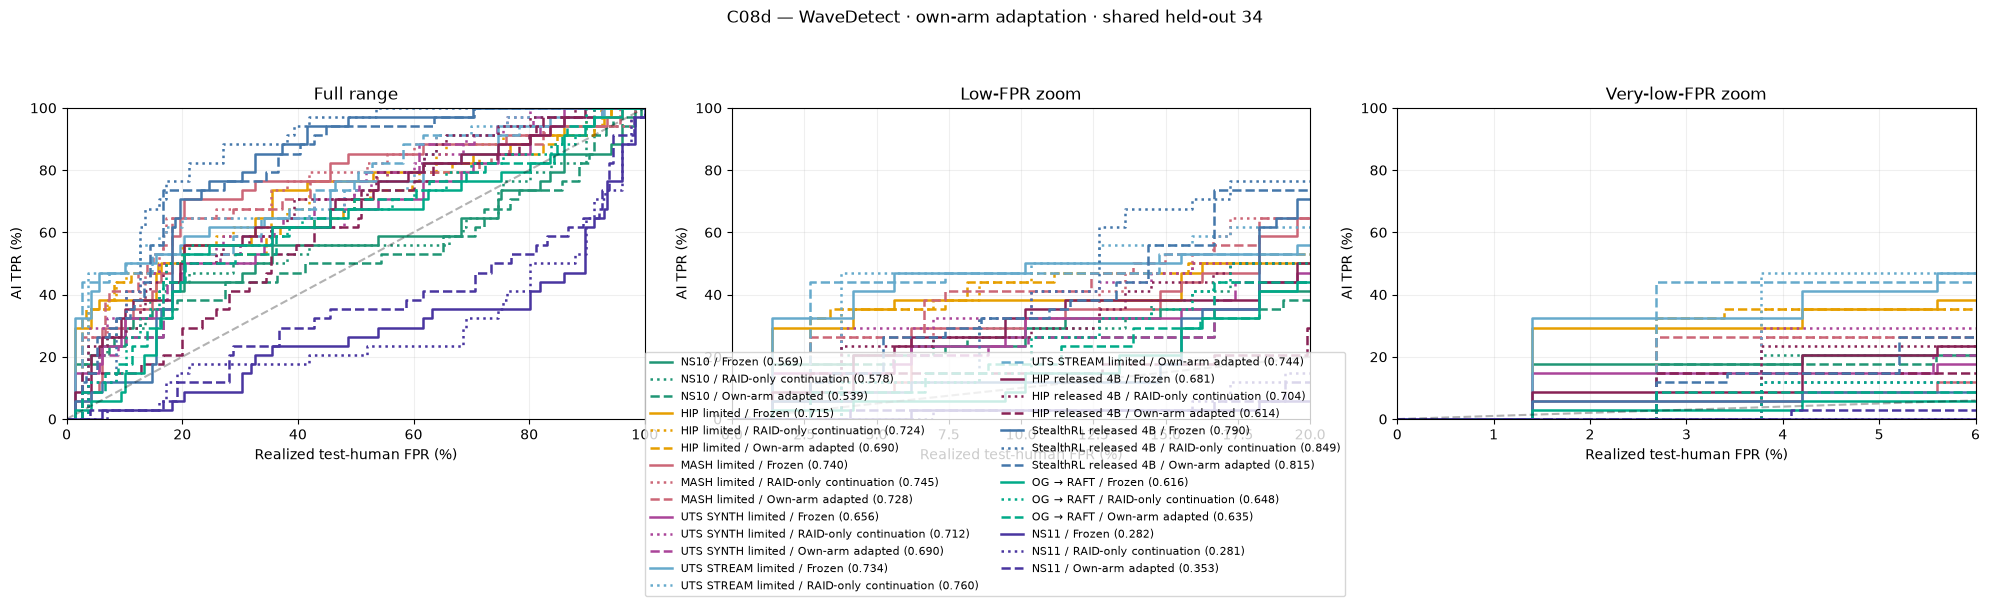

Saved: ../results/causal/C08d_WaveDetect_competitors_RAFT_NS11_v1


In [8]:
original_train=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
all_rows=[];all_stairs=[];all_curves=[];all_changes=[]
with run_lock():
 if selected:
  control=OUT/'RAID_only_continuation'
  cp=continue_model(original_train,control);ck=file_sha(cp)
  control_h=score_frame(raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])],'humans',control,ck)
  control_scores={k:score_frame(frames[k].loc[frames[k].case_id.isin(held)],k,control,ck) for k in selected}
 for arm in selected:
  f=frames[arm];attack=f.loc[f.case_id.isin(chosen)].assign(label=1)
  fitting=pd.concat([original_train,attack],ignore_index=True)
  folder=OUT/arm
  cp=continue_model(fitting,folder);mk=file_sha(cp)
  ah=score_frame(raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])],'humans',folder,mk)
  ae=score_frame(f.loc[f.case_id.isin(held)],'heldout34',folder,mk)
  results=[('Frozen',frozen_scores[arm].loc[frozen_scores[arm].case_id.isin(held)],R.loc[R.label.eq(0)]),
           ('RAID-only continuation',control_scores[arm],control_h),('Own-arm adapted',ae,ah)]
  cc={}
  for name,e,hh in results:
   H=hh;e=e.sort_values('case_id');assert len(e)==34 and e.case_id.tolist()==sorted(held)
   v,h=references(e)
   row,st,z=measure(e,v,h,e.AI_score.to_numpy(),v.AI_score.to_numpy(),h.AI_score.to_numpy(),arm,name)
   cc[name]=z;all_rows.append(row);all_stairs.append(st);all_curves.append((arm,name,st,row['AUROC']))
   save_csv(v,folder/(name.replace(' ','_')+'_validation_humans.csv'))
   save_csv(h,folder/(name.replace(' ','_')+'_test_humans.csv'))
  ix=np.random.default_rng(ADAPT_SEED).integers(0,34,(5000,34))
  for ref in ['Frozen','RAID-only continuation']:
   d=cc['Own-arm adapted']-cc[ref];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
   all_changes.append(dict(arm=arm,comparison='Own-arm adapted minus '+ref,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
  save_csv(pd.DataFrame(all_rows),OUT/'adaptive34_summary.csv')
  save_csv(pd.concat(all_stairs),OUT/'adaptive34_staircases.csv')
  save_csv(pd.DataFrame(all_changes),OUT/'adaptive34_paired_changes.csv')
if selected:
 display(pd.DataFrame(all_rows).round(6));display(pd.DataFrame(all_changes).round(6))
 plot_curves(all_curves,'C08d — WaveDetect · own-arm adaptation · shared held-out 34','C08d_WaveDetect_adaptation34',COLORS)
else:print('No arms meet selection rule.')
print('Saved:',OUT)
